In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

os.makedirs("outputs", exist_ok=True)

# Download the VADER sentiment lexicon
nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\gopik\AppData\Roaming\nltk_data...


True

In [2]:
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

# Clean column names
apps.columns = apps.columns.str.strip()
reviews.columns = reviews.columns.str.strip()

print("Apps dataset shape:", apps.shape)
print("Reviews dataset shape:", reviews.shape)

print("\nApp columns:")
print(apps.columns.tolist())

print("\nReview columns:")
print(reviews.columns.tolist())

display(apps.head())
display(reviews.head())

Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)

App columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Review columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [3]:
print("Apps data types:")
print(apps.dtypes)

print("\nMissing values in apps:")
display(apps.isnull().sum().sort_values(ascending=False))

print("\nMissing values in reviews:")
display(reviews.isnull().sum().sort_values(ascending=False))

Apps data types:
App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

Missing values in apps:


Rating            1474
Current Ver          8
Android Ver          3
Content Rating       1
Type                 1
Size                 0
Reviews              0
Category             0
App                  0
Price                0
Installs             0
Last Updated         0
Genres               0
dtype: int64


Missing values in reviews:


Translated_Review         26868
Sentiment_Polarity        26863
Sentiment                 26863
Sentiment_Subjectivity    26863
App                           0
dtype: int64

In [4]:
apps["App"] = apps["App"].astype("string").str.strip()
apps["Category"] = apps["Category"].astype("string").str.strip().str.upper()

# Remove rows without essential identifiers
apps = apps.dropna(subset=["App", "Category"])

# Remove exact duplicate rows
apps = apps.drop_duplicates()

# Keep one record per app name for this descriptive analysis
apps = apps.drop_duplicates(subset=["App"], keep="first")

print("Cleaned apps shape:", apps.shape)

Cleaned apps shape: (9660, 13)


In [5]:
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")

if "Reviews" in apps.columns:
    apps["Reviews"] = pd.to_numeric(
        apps["Reviews"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

print(apps[["App", "Rating", "Reviews"]].head())

                                                 App  Rating  Reviews
0     Photo Editor & Candy Camera & Grid & ScrapBook     4.1      159
1                                Coloring book moana     3.9      967
2  U Launcher Lite – FREE Live Cool Themes, Hide ...     4.7    87510
3                              Sketch - Draw & Paint     4.5   215644
4              Pixel Draw - Number Art Coloring Book     4.3      967


In [6]:
apps.loc[~apps["Rating"].between(1, 5), "Rating"] = np.nan

In [7]:
apps["Installs"] = pd.to_numeric(
    apps["Installs"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.replace("+", "", regex=False)
        .str.strip(),
    errors="coerce"
)

print(apps[["App", "Installs"]].head())

                                                 App  Installs
0     Photo Editor & Candy Camera & Grid & ScrapBook     10000
1                                Coloring book moana    500000
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   5000000
3                              Sketch - Draw & Paint  50000000
4              Pixel Draw - Number Art Coloring Book    100000


In [8]:
if "Price" in apps.columns:
    apps["Price"] = pd.to_numeric(
        apps["Price"]
            .astype("string")
            .str.replace("$", "", regex=False)
            .str.strip(),
        errors="coerce"
    )

if "Type" in apps.columns:
    apps["Type"] = apps["Type"].astype("string").str.strip().str.title()

# Normalize Free/Paid using the numeric price where possible
apps.loc[apps["Price"] == 0, "Type"] = "Free"
apps.loc[apps["Price"] > 0, "Type"] = "Paid"

print(apps[["App", "Type", "Price"]].head())

                                                 App  Type  Price
0     Photo Editor & Candy Camera & Grid & ScrapBook  Free    0.0
1                                Coloring book moana  Free    0.0
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  Free    0.0
3                              Sketch - Draw & Paint  Free    0.0
4              Pixel Draw - Number Art Coloring Book  Free    0.0


In [9]:
def size_to_mb(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"varies with device", "nan", ""}:
        return np.nan

    try:
        if value.endswith("m"):
            return float(value[:-1])
        elif value.endswith("k"):
            return float(value[:-1]) / 1024
        else:
            return float(value)
    except ValueError:
        return np.nan

apps["Size_MB"] = apps["Size"].apply(size_to_mb)

display(apps[["App", "Size", "Size_MB"]].head(10))

,App,Size,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,19M,19.0
1,Coloring book moana,14M,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",8.7M,8.7
3,Sketch - Draw & Paint,25M,25.0
4,Pixel Draw - Number Art Coloring Book,2.8M,2.8
5,Paper flowers instructions,5.6M,5.6
6,Smoke Effect Photo Maker - Smoke Editor,19M,19.0
7,Infinite Painter,29M,29.0
8,Garden Coloring Book,33M,33.0
9,Kids Paint Free - Drawing Fun,3.1M,3.1


In [10]:
print("Final shape:", apps.shape)
print("\nMissing values:")
display(apps.isnull().sum().sort_values(ascending=False))

print("\nNumeric summary:")
display(apps[["Rating", "Reviews", "Size_MB", "Installs", "Price"]].describe())

Final shape: (9660, 14)

Missing values:


Rating            1464
Size_MB           1228
Current Ver          8
Android Ver          3
Installs             1
Reviews              1
Content Rating       1
Price                1
App                  0
Category             0
Size                 0
Type                 0
Genres               0
Last Updated         0
dtype: int64


Numeric summary:


,Rating,Reviews,Size_MB,Installs,Price
count,8196.000000,9659.0,8432.000000,9659.0,9659.0
mean,4.173243,216592.563826,20.394897,7777506.73227,1.099299
std,0.536625,1831319.566176,21.827898,53758278.683523,16.852152
min,1.000000,0.0,0.008301,0.0,0.0
25%,4.000000,25.0,4.600000,1000.0,0.0
50%,4.300000,967.0,12.000000,100000.0,0.0
75%,4.500000,29401.0,28.000000,1000000.0,0.0
max,5.000000,78158306.0,100.000000,1000000000.0,400.0


,Category,App_Count
0,FAMILY,1832
1,GAME,959
2,TOOLS,827
3,BUSINESS,420
4,MEDICAL,395
5,PERSONALIZATION,376
6,PRODUCTIVITY,374
7,LIFESTYLE,369
8,FINANCE,345
9,SPORTS,325


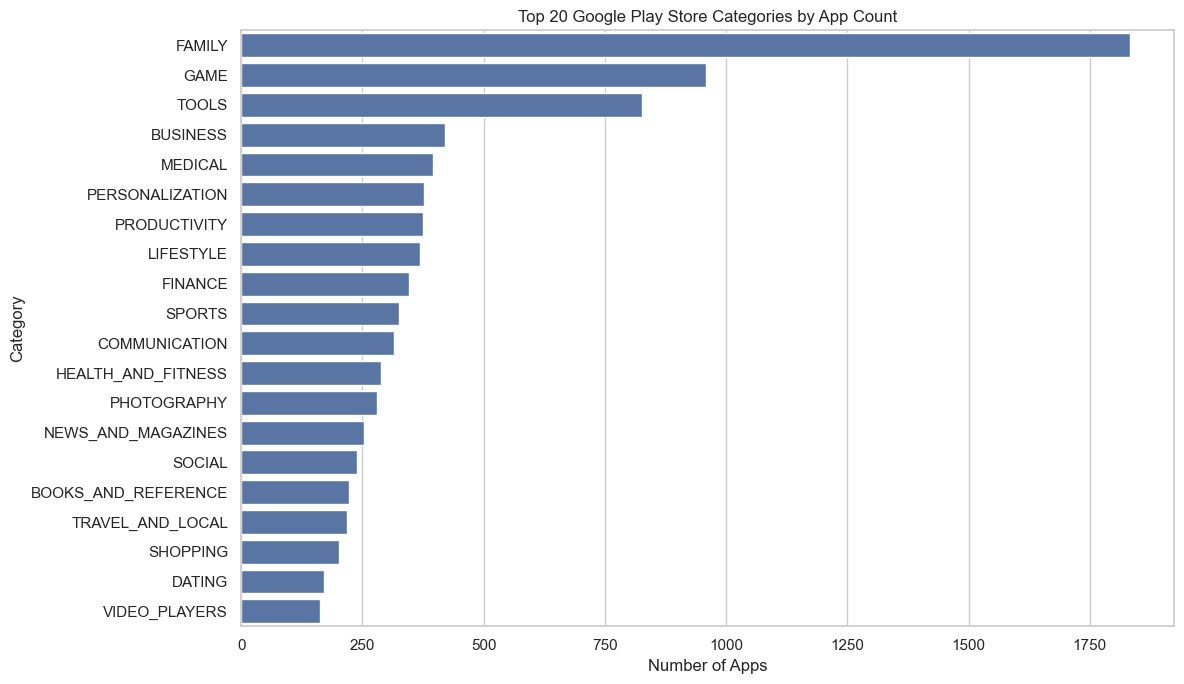

In [11]:
category_counts = (
    apps["Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="App_Count")
)

display(category_counts.head(15))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=category_counts.head(20),
    x="App_Count",
    y="Category"
)

plt.title("Top 20 Google Play Store Categories by App Count")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

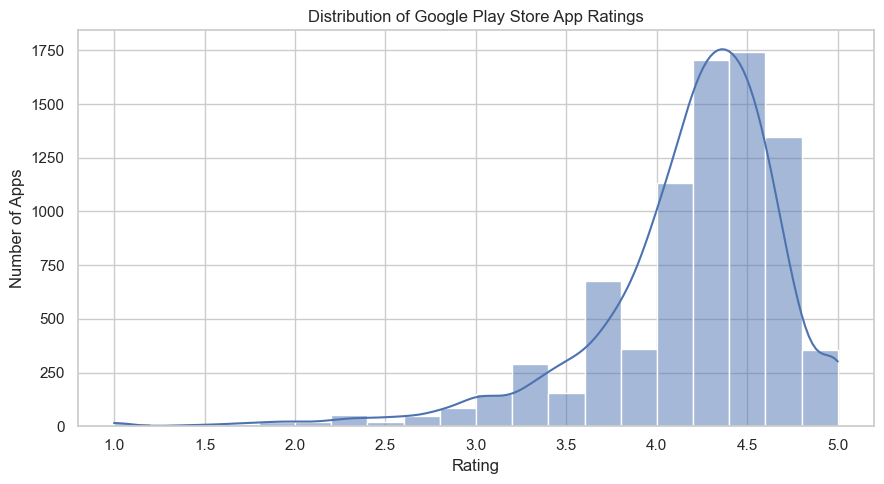

Average app rating: 4.17
Median app rating: 4.3


In [12]:
rating_data = apps.dropna(subset=["Rating"])

plt.figure(figsize=(9, 5))
sns.histplot(data=rating_data, x="Rating", bins=20, kde=True)

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

print("Average app rating:", round(rating_data["Rating"].mean(), 2))
print("Median app rating:", round(rating_data["Rating"].median(), 2))

,Category,Average_Rating,Rated_Apps,Median_Rating
11,EVENTS,4.44,45,4.5
9,EDUCATION,4.36,118,4.4
1,ART_AND_DESIGN,4.36,61,4.4
4,BOOKS_AND_REFERENCE,4.34,169,4.5
24,PERSONALIZATION,4.33,298,4.4
23,PARENTING,4.30,50,4.4
3,BEAUTY,4.28,42,4.3
15,GAME,4.25,912,4.3
28,SOCIAL,4.25,203,4.3
33,WEATHER,4.24,72,4.3


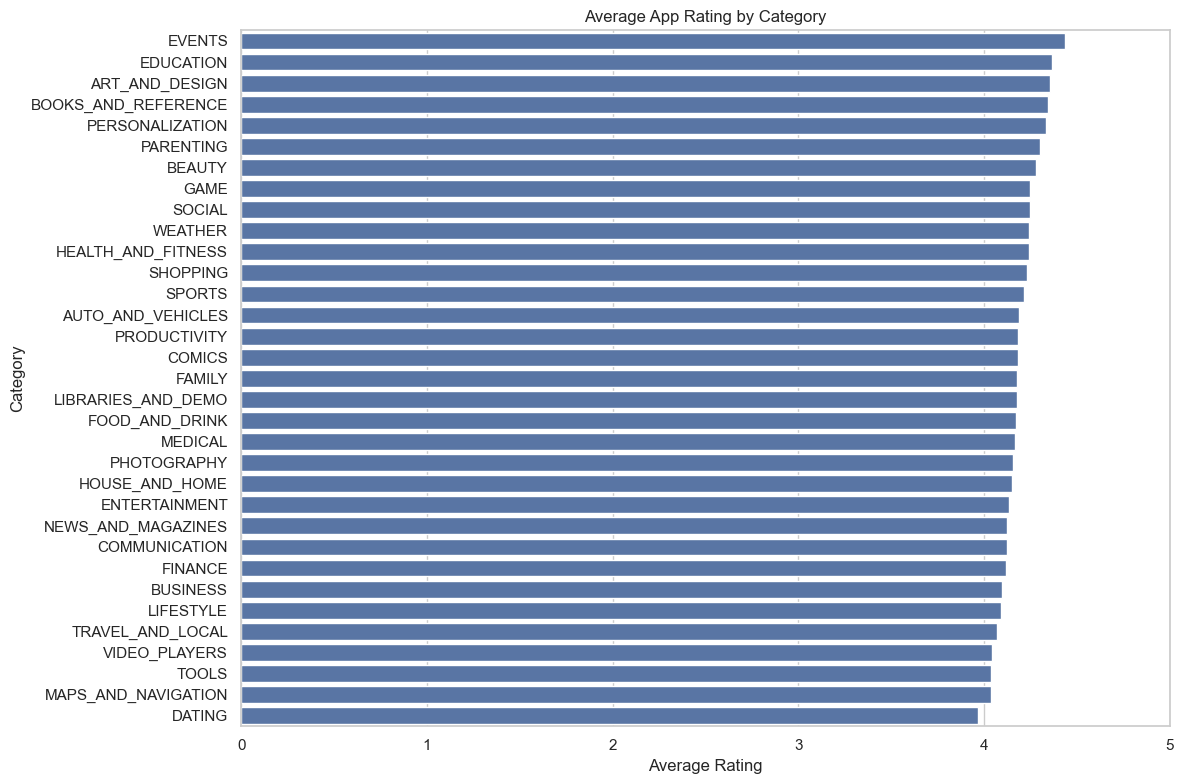

In [13]:
category_ratings = (
    apps.groupby("Category")
    .agg(
        Average_Rating=("Rating", "mean"),
        Rated_Apps=("Rating", "count"),
        Median_Rating=("Rating", "median")
    )
    .reset_index()
    .sort_values("Average_Rating", ascending=False)
)

display(category_ratings.round(2))

# Only show categories with at least 10 rated apps
plot_ratings = category_ratings[
    category_ratings["Rated_Apps"] >= 10
].sort_values("Average_Rating", ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=plot_ratings,
    x="Average_Rating",
    y="Category"
)

plt.xlim(0, 5)
plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

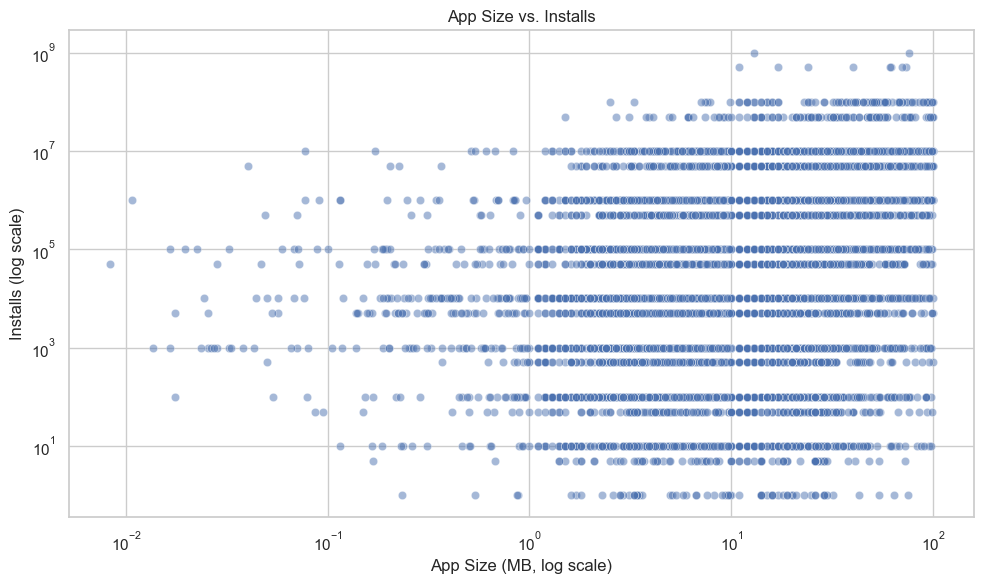

In [14]:
size_install_data = apps.dropna(subset=["Size_MB", "Installs"]).copy()

size_install_data = size_install_data[
    (size_install_data["Size_MB"] > 0) &
    (size_install_data["Installs"] > 0)
]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=size_install_data,
    x="Size_MB",
    y="Installs",
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")
plt.title("App Size vs. Installs")
plt.xlabel("App Size (MB, log scale)")
plt.ylabel("Installs (log scale)")
plt.tight_layout()
plt.show()

In [15]:
size_install_data["Log_Size"] = np.log1p(size_install_data["Size_MB"])
size_install_data["Log_Installs"] = np.log1p(size_install_data["Installs"])

pearson_corr = size_install_data[
    ["Log_Size", "Log_Installs"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = size_install_data[
    ["Size_MB", "Installs"]
].corr(method="spearman").iloc[0, 1]

print(f"Pearson correlation on log-transformed values: {pearson_corr:.3f}")
print(f"Spearman rank correlation: {spearman_corr:.3f}")

Pearson correlation on log-transformed values: 0.300
Spearman rank correlation: 0.310


Type
Free    8903
Paid     756
0          1
Name: count, dtype: int64[pyarrow]


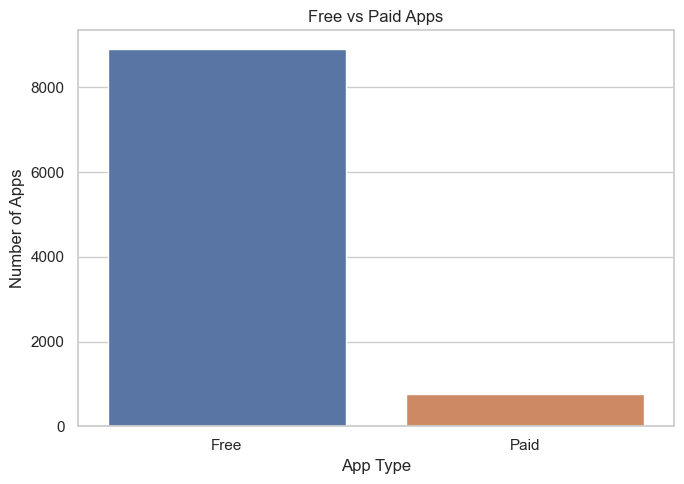

In [16]:
type_counts = apps["Type"].value_counts(dropna=False)

print(type_counts)

plt.figure(figsize=(7, 5))
sns.countplot(
    data=apps,
    x="Type",
    hue="Type",
    legend=False,
    order=["Free", "Paid"]
)

plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

Number of paid apps: 756


,Price
count,756.0
mean,14.05
std,58.74
min,0.99
25%,1.49
50%,2.99
75%,4.99
max,400.0


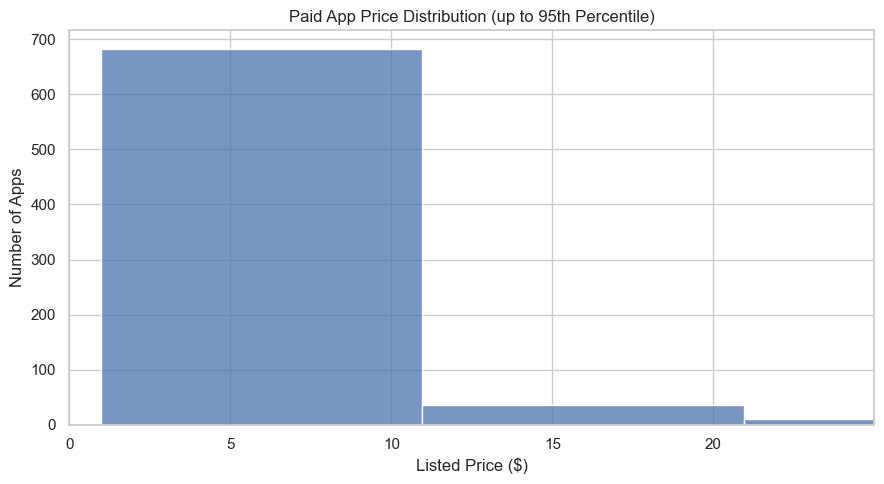

In [17]:
paid_apps = apps[
    (apps["Type"] == "Paid") &
    (apps["Price"] > 0)
].copy()

print("Number of paid apps:", len(paid_apps))

display(
    paid_apps["Price"]
    .describe()
    .to_frame("Price")
    .round(2)
)

plt.figure(figsize=(9, 5))
sns.histplot(data=paid_apps, x="Price", bins=40)

plt.xlim(0, paid_apps["Price"].quantile(0.95) if len(paid_apps) else 1)
plt.title("Paid App Price Distribution (up to 95th Percentile)")
plt.xlabel("Listed Price ($)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

,Category,Paid_App_Count,Median_Price,Estimated_Gross_Value
9,FAMILY,183,2.99,113679845.36
15,LIFESTYLE,19,4.99,57583939.4
12,GAME,82,2.74,40688636.85
10,FINANCE,17,28.99,25726678.98
21,PHOTOGRAPHY,19,3.49,8547767.7
20,PERSONALIZATION,81,1.49,6796947.56
17,MEDICAL,83,4.99,5957535.67
26,TOOLS,78,2.77,5464820.59
25,SPORTS,24,2.99,4706211.95
22,PRODUCTIVITY,28,2.99,4313374.95


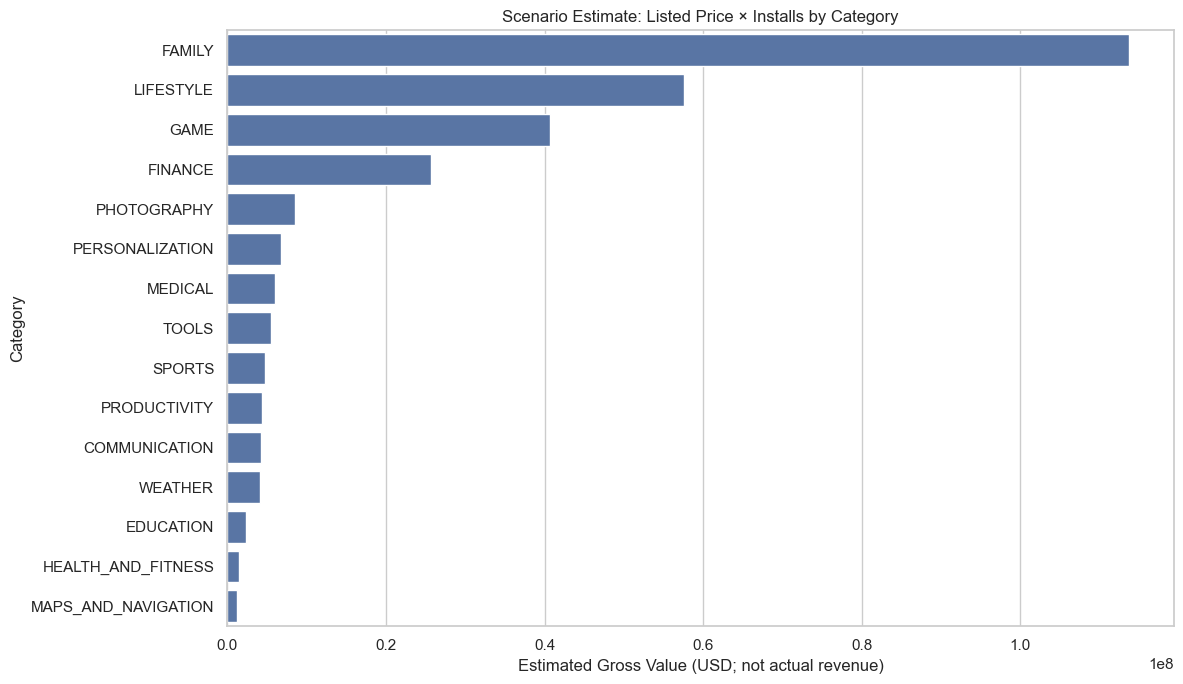

In [18]:
paid_apps["Estimated_Gross_Value"] = (
    paid_apps["Price"] * paid_apps["Installs"]
)

revenue_by_category = (
    paid_apps.groupby("Category")
    .agg(
        Paid_App_Count=("App", "count"),
        Median_Price=("Price", "median"),
        Estimated_Gross_Value=("Estimated_Gross_Value", "sum")
    )
    .reset_index()
    .sort_values("Estimated_Gross_Value", ascending=False)
)

display(revenue_by_category.head(15).round(2))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=revenue_by_category.head(15),
    x="Estimated_Gross_Value",
    y="Category"
)

plt.title("Scenario Estimate: Listed Price × Installs by Category")
plt.xlabel("Estimated Gross Value (USD; not actual revenue)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [19]:
print("Review columns:", reviews.columns.tolist())

# Inspect a few reviews
display(reviews.head())

# Remove rows without usable review text
reviews["App"] = reviews["App"].astype("string").str.strip()
reviews["Translated_Review"] = reviews["Translated_Review"].astype("string").str.strip()

reviews = reviews.dropna(subset=["App", "Translated_Review"])

reviews = reviews[
    reviews["Translated_Review"].str.len() > 0
].copy()

# Remove duplicate app-review pairs
reviews = reviews.drop_duplicates(
    subset=["App", "Translated_Review"]
)

print("Cleaned reviews shape:", reviews.shape)
display(reviews[["App", "Translated_Review"]].head())

Review columns: ['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


Cleaned reviews shape: (29692, 5)


,App,Translated_Review
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...
1,10 Best Foods for You,This help eating healthy exercise regular basis
3,10 Best Foods for You,Works great especially going grocery store
4,10 Best Foods for You,Best idea us
5,10 Best Foods for You,Best way


In [20]:
analyzer = SentimentIntensityAnalyzer()

# Calculate sentiment scores
sentiment_scores = reviews["Translated_Review"].apply(
    lambda text: analyzer.polarity_scores(str(text))
)

sentiment_scores_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=reviews.index
)

reviews = pd.concat(
    [reviews, sentiment_scores_df],
    axis=1
)

def classify_sentiment(compound_score):
    if compound_score >= 0.05:
        return "Positive"
    elif compound_score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews["VADER_Sentiment"] = reviews["compound"].apply(
    classify_sentiment
)

display(
    reviews[
        ["App", "Translated_Review", "neg", "neu", "pos",
         "compound", "VADER_Sentiment"]
    ].head(10)
)

,App,Translated_Review,neg,neu,pos,compound,VADER_Sentiment
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,0.000,0.466,0.534,0.9531,Positive
1,10 Best Foods for You,This help eating healthy exercise regular basis,0.000,0.481,0.519,0.6597,Positive
3,10 Best Foods for You,Works great especially going grocery store,0.000,0.549,0.451,0.6249,Positive
4,10 Best Foods for You,Best idea us,0.000,0.323,0.677,0.6369,Positive
5,10 Best Foods for You,Best way,0.000,0.192,0.808,0.6369,Positive
6,10 Best Foods for You,Amazing,0.000,0.000,1.000,0.5859,Positive
8,10 Best Foods for You,"Looking forward app,",0.000,1.000,0.000,0.0000,Neutral
9,10 Best Foods for You,It helpful site ! It help foods get !,0.000,0.451,0.549,0.7256,Positive
10,10 Best Foods for You,good you.,0.000,0.256,0.744,0.4404,Positive
11,10 Best Foods for You,Useful information The amount spelling errors ...,0.128,0.588,0.283,0.4404,Positive


,Review_Count
VADER_Sentiment,
Positive,20129
Neutral,3711
Negative,5852


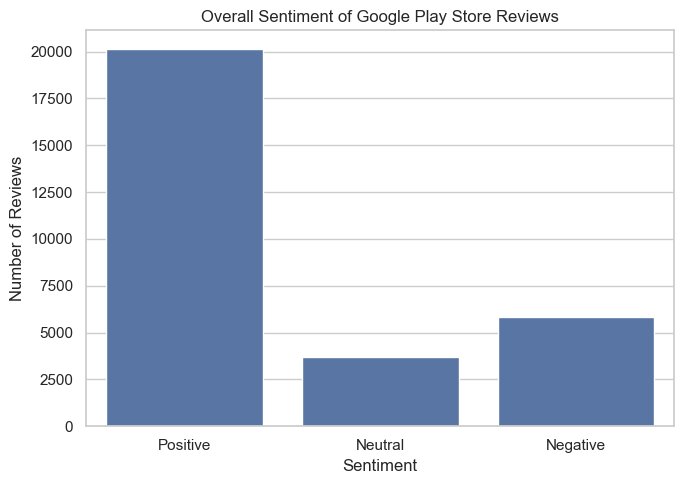

In [21]:
sentiment_counts = (
    reviews["VADER_Sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

display(sentiment_counts.to_frame("Review_Count"))

plt.figure(figsize=(7, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Overall Sentiment of Google Play Store Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [22]:
sentiment_percentages = (
    reviews["VADER_Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

display(sentiment_percentages.round(2).to_frame("Percentage"))

,Percentage
VADER_Sentiment,
Positive,67.79
Neutral,12.50
Negative,19.71


In [23]:
# Build an app-to-category lookup from the cleaned app dataset
app_categories = apps[["App", "Category"]].drop_duplicates("App")

reviews_with_category = reviews.merge(
    app_categories,
    on="App",
    how="left"
)

print(
    "Reviews matched to a category:",
    f"{reviews_with_category['Category'].notna().mean() * 100:.2f}%"
)

display(reviews_with_category.head())

Reviews matched to a category: 95.14%


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,neg,neu,pos,compound,VADER_Sentiment,Category
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333,0.0,0.466,0.534,0.9531,Positive,HEALTH_AND_FITNESS
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462,0.0,0.481,0.519,0.6597,Positive,HEALTH_AND_FITNESS
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000,0.0,0.549,0.451,0.6249,Positive,HEALTH_AND_FITNESS
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000,0.0,0.323,0.677,0.6369,Positive,HEALTH_AND_FITNESS
4,10 Best Foods for You,Best way,Positive,1.00,0.300000,0.0,0.192,0.808,0.6369,Positive,HEALTH_AND_FITNESS


In [24]:
category_sentiment = (
    reviews_with_category.dropna(subset=["Category"])
    .groupby("Category")
    .agg(
        Review_Count=("VADER_Sentiment", "size"),
        Positive_Rate=(
            "VADER_Sentiment",
            lambda s: (s == "Positive").mean() * 100
        ),
        Negative_Rate=(
            "VADER_Sentiment",
            lambda s: (s == "Negative").mean() * 100
        ),
        Neutral_Rate=(
            "VADER_Sentiment",
            lambda s: (s == "Neutral").mean() * 100
        ),
        Mean_Compound=("compound", "mean")
    )
    .reset_index()
    .sort_values("Positive_Rate", ascending=False)
)

display(category_sentiment.round(2))

,Category,Review_Count,Positive_Rate,Negative_Rate,Neutral_Rate,Mean_Compound
5,COMICS,45,86.67,2.22,11.11,0.54
1,AUTO_AND_VEHICLES,283,81.98,4.95,13.07,0.51
10,EVENTS,156,79.49,12.18,8.33,0.44
15,HEALTH_AND_FITNESS,1621,77.91,13.57,8.51,0.48
8,EDUCATION,644,77.64,11.02,11.34,0.47
0,ART_AND_DESIGN,354,74.58,13.28,12.15,0.42
13,FOOD_AND_DRINK,583,74.27,14.75,10.98,0.43
14,GAME,4344,73.14,20.83,6.03,0.39
22,PARENTING,256,73.05,10.94,16.02,0.45
11,FAMILY,1802,72.86,16.76,10.38,0.39


In [25]:
MIN_REVIEWS = 50

eligible_categories = category_sentiment[
    category_sentiment["Review_Count"] >= MIN_REVIEWS
].copy()

top_positive = eligible_categories.sort_values(
    "Positive_Rate", ascending=False
).head(10)

top_negative = eligible_categories.sort_values(
    "Negative_Rate", ascending=False
).head(10)

print("Categories with the highest positive review rates:")
display(top_positive.round(2))

print("Categories with the highest negative review rates:")
display(top_negative.round(2))

Categories with the highest positive review rates:


,Category,Review_Count,Positive_Rate,Negative_Rate,Neutral_Rate,Mean_Compound
1,AUTO_AND_VEHICLES,283,81.98,4.95,13.07,0.51
10,EVENTS,156,79.49,12.18,8.33,0.44
15,HEALTH_AND_FITNESS,1621,77.91,13.57,8.51,0.48
8,EDUCATION,644,77.64,11.02,11.34,0.47
0,ART_AND_DESIGN,354,74.58,13.28,12.15,0.42
13,FOOD_AND_DRINK,583,74.27,14.75,10.98,0.43
14,GAME,4344,73.14,20.83,6.03,0.39
22,PARENTING,256,73.05,10.94,16.02,0.45
11,FAMILY,1802,72.86,16.76,10.38,0.39
3,BOOKS_AND_REFERENCE,617,72.29,15.88,11.83,0.38


Categories with the highest negative review rates:


,Category,Review_Count,Positive_Rate,Negative_Rate,Neutral_Rate,Mean_Compound
27,SOCIAL,661,54.92,31.62,13.46,0.17
31,VIDEO_PLAYERS,326,55.83,31.60,12.58,0.18
9,ENTERTAINMENT,827,57.56,27.57,14.87,0.23
21,NEWS_AND_MAGAZINES,733,57.57,25.51,16.92,0.20
6,COMMUNICATION,855,61.64,25.03,13.33,0.25
12,FINANCE,1336,66.02,24.03,9.96,0.29
28,SPORTS,1216,65.79,22.62,11.60,0.30
7,DATING,1087,62.83,22.45,14.72,0.27
26,SHOPPING,649,67.03,22.03,10.94,0.33
30,TRAVEL_AND_LOCAL,1331,63.79,21.86,14.35,0.28


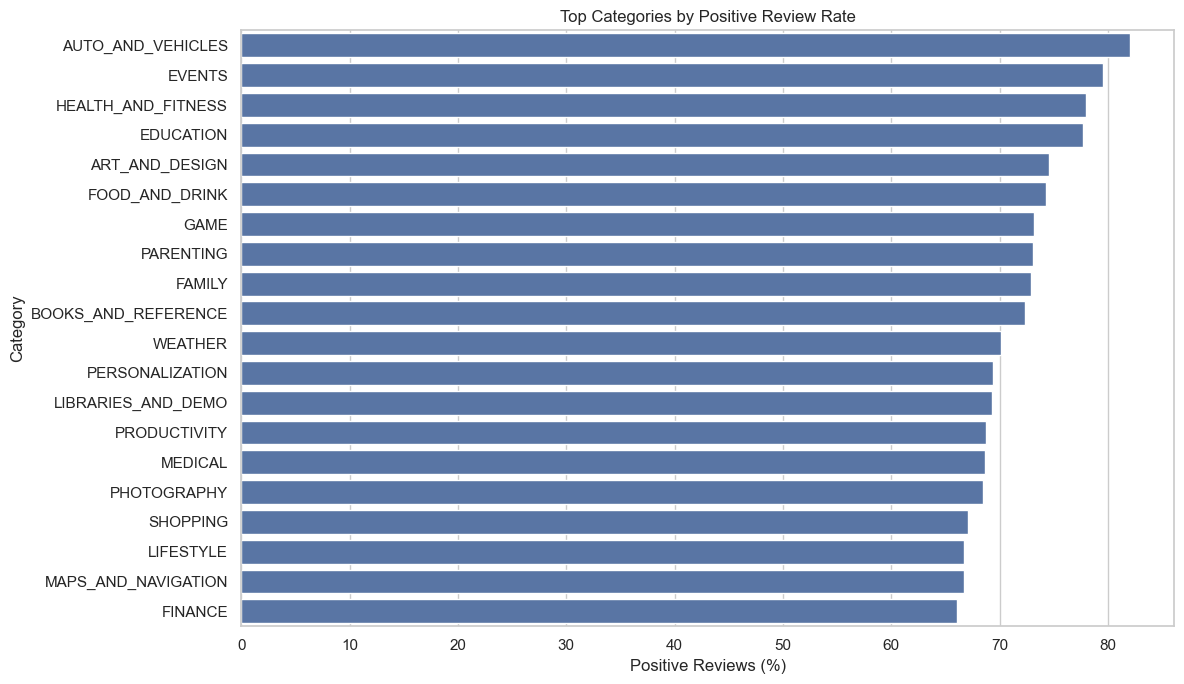

In [26]:
plt.figure(figsize=(12, 7))

plot_data = eligible_categories.sort_values(
    "Positive_Rate", ascending=False
).head(20)

sns.barplot(
    data=plot_data,
    x="Positive_Rate",
    y="Category"
)

plt.title("Top Categories by Positive Review Rate")
plt.xlabel("Positive Reviews (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

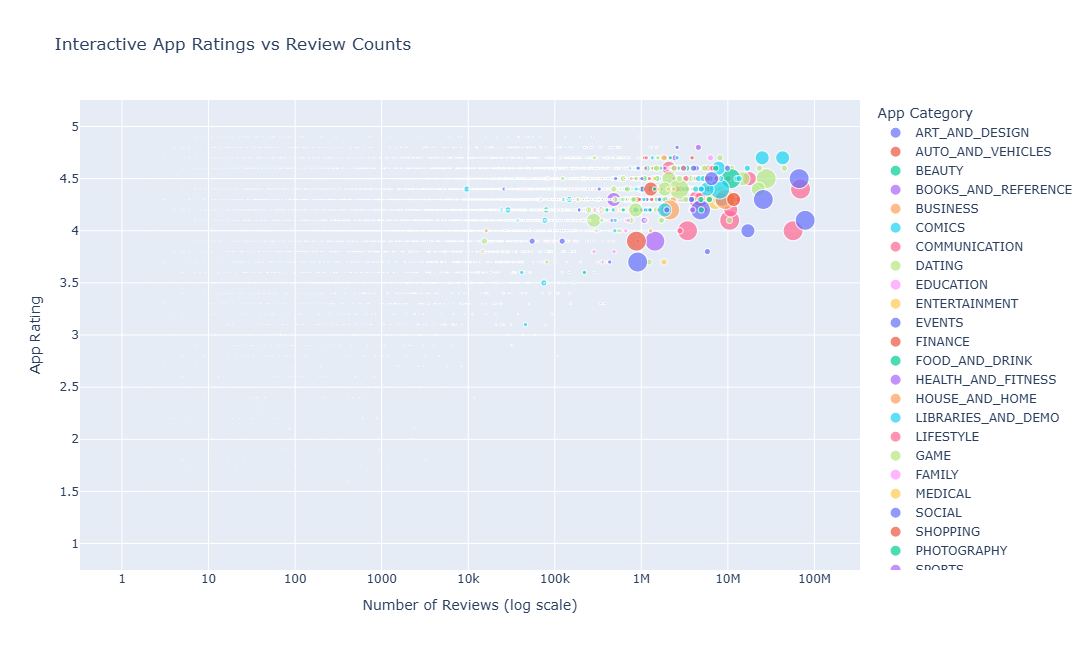

In [27]:
interactive_apps = apps.dropna(
    subset=["Rating", "Installs", "Reviews", "Category"]
).copy()

interactive_apps = interactive_apps[
    (interactive_apps["Installs"] > 0) &
    (interactive_apps["Reviews"] >= 0)
]

fig = px.scatter(
    interactive_apps,
    x="Reviews",
    y="Rating",
    color="Category",
    size="Installs",
    hover_name="App",
    log_x=True,
    title="Interactive App Ratings vs Review Counts",
    labels={
        "Reviews": "Number of Reviews (log scale)",
        "Rating": "App Rating",
        "Installs": "Approximate Installs"
    }
)

fig.update_layout(
    height=650,
    legend_title_text="App Category"
)

fig.show()

In [28]:
fig.write_html("outputs/interactive_app_ratings.html")
print("Interactive chart saved.")

Interactive chart saved.


In [29]:
# Insight 1: Most crowded categories
print("INSIGHT 1 — CATEGORY SATURATION")

display(
    category_counts.head(5).rename(
        columns={"Category": "Category", "App_Count": "Number_of_Apps"}
    )
)

# Insight 2: Highest-rated categories with sufficient sample size
print("\nINSIGHT 2 — CATEGORY RATINGS")

display(
    plot_ratings[
        ["Category", "Average_Rating", "Rated_Apps"]
    ].head(5).round(2)
)

# Insight 3: Category sentiment
print("\nINSIGHT 3 — USER SENTIMENT")

display(
    eligible_categories.sort_values(
        ["Positive_Rate", "Review_Count"],
        ascending=[False, False]
    )[
        ["Category", "Review_Count", "Positive_Rate", "Negative_Rate"]
    ].head(5).round(2)
)

INSIGHT 1 — CATEGORY SATURATION


,Category,Number_of_Apps
0,FAMILY,1832
1,GAME,959
2,TOOLS,827
3,BUSINESS,420
4,MEDICAL,395



INSIGHT 2 — CATEGORY RATINGS


,Category,Average_Rating,Rated_Apps
11,EVENTS,4.44,45
9,EDUCATION,4.36,118
1,ART_AND_DESIGN,4.36,61
4,BOOKS_AND_REFERENCE,4.34,169
24,PERSONALIZATION,4.33,298



INSIGHT 3 — USER SENTIMENT


,Category,Review_Count,Positive_Rate,Negative_Rate
1,AUTO_AND_VEHICLES,283,81.98,4.95
10,EVENTS,156,79.49,12.18
15,HEALTH_AND_FITNESS,1621,77.91,13.57
8,EDUCATION,644,77.64,11.02
0,ART_AND_DESIGN,354,74.58,13.28


In [30]:
apps.to_csv("outputs/cleaned_apps.csv", index=False)

reviews_with_category.to_csv(
    "outputs/reviews_with_vader_sentiment.csv",
    index=False
)

category_counts.to_csv(
    "outputs/category_app_counts.csv",
    index=False
)

category_ratings.to_csv(
    "outputs/category_ratings.csv",
    index=False
)

category_sentiment.to_csv(
    "outputs/category_sentiment.csv",
    index=False
)

revenue_by_category.to_csv(
    "outputs/estimated_paid_app_value_by_category.csv",
    index=False
)

print("All analysis outputs saved successfully.")

All analysis outputs saved successfully.
